# Dreaming to plan faster under an unknown range of motion

## The setting

A two-link planar arm is asked to reach goals in 2D task space. Its joint limits — its **range of motion (ROM)** — are unknown to the agent. Think of the arm as a stand-in for a person whose reach we are learning: the robot has to help them accomplish tasks while it is still uncertain about what they can do.

There are four hidden numbers: a lower and upper limit for each of the two joints. The agent maintains a **belief** over them (represented with particles), plans with **random shooting** by evaluating candidate action sequences in expectation over belief particles, executes, observes what happened, and updates the belief.

## The idea: alternate between learning to plan faster and learning about the world

Planning from scratch every episode is expensive. But the agent knows something about what it will believe in the future: its future belief is its current belief refined by observations it can already imagine. So between episodes the agent **dreams**:

1. sample a hypothesis of the true ROM from the current belief and pretend it is the truth;
2. imagine executing a plan for a likely upcoming goal on that hypothetical arm, and update a *copy* of the belief with the imagined observations;
3. solve the goals of the task distribution under that imagined future belief, and **memorize** the solutions in a cache keyed on (goal, belief).

When the real future arrives, if the realized belief matches one the agent dreamed about, planning is a lookup plus a quick refinement instead of a search from scratch.

Two properties we want to see empirically:

- **P1.** With enough dream samples, planning becomes very fast.
- **P2.** With enough real executions, the belief collapses to the true ROM.

Information gathering in this notebook is **incidental**: the agent never plans in order to learn; it learns because reaching for goals near the edge of the range of motion happens to bump into the limits.

## Contents

- §1 Arm model and forward kinematics
- §2 Belief over the range of motion, and the observation model
- §3 Planner: random shooting with an optional warm-start cache
- §4 Warm-up: one goal, no uncertainty — a cache lookup beats planning from scratch
- §5 Full loop: dream → plan → execute → update
- §6 Sweep: how many dreams do we need? (P1)
- §7 Belief collapse over executions (P2)
- §8 Suggestions for extensions

Everything is numpy; the full notebook runs in roughly 10 minutes (the 12-seed sweep in §6 is the slow part — reduce `SEEDS` there for a quick pass).

In [1]:
import numpy as np, time
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 10, 'legend.frameon': False})
C = {'scratch': '#888888', 'memo': '#1f77b4', 'dream': '#d62728', 'belief': '#2ca02c', 'goal': '#ff7f0e'}

rng = np.random.default_rng(0)

L1, L2 = 1.0, 1.0      # link lengths
H = 15                 # plan horizon (steps)
DQ_MAX = 0.3           # max joint change per step (rad)
TOL = 1e-6

# Prior over joint limits, independent per limit:  lo_i ~ U[-pi, -0.5],  hi_i ~ U[0.5, pi].
# Row order: [lo1, hi1, lo2, hi2].
PRIOR = np.array([[-np.pi, -0.5], [0.5, np.pi], [-np.pi, -0.5], [0.5, np.pi]])


## 1. Arm model

The arm is **kinematic**: an action is a joint displacement $a \in [-a_{\max}, a_{\max}]^2$ applied in one step. The hidden joint limits clip the motion:

$$ q_{t+1} = \mathrm{clip}(q_t + a_t,\; q_{\text{lo}},\; q_{\text{hi}}). $$

The mass of the links does not appear anywhere in this model, which is why hidden *dynamics* parameters would not be a good unknown here: nothing the agent observes would depend on them. The joint limits are a good unknown precisely because they change which motions are possible.

`rollout` simulates a batch of `K` action sequences under a batch of `P` limit hypotheses at once (shape `(K, P, 2)`), which is what the planner needs to take expectations over the belief.

In [2]:
def fk(q):
    # q: (..., 2) joint angles -> (..., 2) end-effector position
    t1 = q[..., 0]; t12 = q[..., 0] + q[..., 1]
    return np.stack([L1*np.cos(t1) + L2*np.cos(t12), L1*np.sin(t1) + L2*np.sin(t12)], -1)

def step(q, a, lim):
    # q: (P, 2), a: (2,) or (P, 2), lim: (P, 4) -> clipped next state (P, 2)
    lo = lim[:, [0, 2]]; hi = lim[:, [1, 3]]
    return np.clip(q + a, lo, hi)

def rollout(q0, actions, lim):
    # actions: (K, H, 2), lim: (P, 4)  ->  final joint state for every (sequence, hypothesis): (K, P, 2)
    K, P = actions.shape[0], lim.shape[0]
    q = np.broadcast_to(q0, (K, P, 2)).copy()
    limb = np.broadcast_to(lim, (K, P, 4)).reshape(K*P, 4)
    for t in range(H):
        a = np.repeat(actions[:, t, :], P, axis=0)
        q = step(q.reshape(K*P, 2), a, limb).reshape(K, P, 2)
    return q

class TrueArm:
    # The real arm. Its limits are hidden from the agent; it only reports its joint state.
    def __init__(self, lim):
        self.lim = np.array(lim, float).reshape(1, 4)
        self.q = np.zeros(2)
    def execute(self, a):
        self.q = step(self.q[None], a, self.lim)[0]
        return self.q.copy()

def draw_arm(ax, q, color='k', alpha=1.0, lw=2.5):
    p1 = np.array([L1*np.cos(q[0]), L1*np.sin(q[0])]); p2 = fk(q)
    ax.plot([0, p1[0], p2[0]], [0, p1[1], p2[1]], '-o', color=color, alpha=alpha, lw=lw, ms=4)

_PIX = np.linspace(-2.2, 2.2, 221)

def workspace_mask(lim, n=400):
    # Occupancy of the reachable end-effector set on a pixel grid, from a fine grid of joint configurations.
    q1 = np.linspace(lim[0], lim[1], n); q2 = np.linspace(lim[2], lim[3], n)
    P = fk(np.stack(np.meshgrid(q1, q2, indexing='ij'), -1).reshape(-1, 2))
    ij = np.clip(np.round((P + 2.2) / 4.4 * (len(_PIX) - 1)).astype(int), 0, len(_PIX) - 1)
    M = np.zeros((len(_PIX), len(_PIX)), bool); M[ij[:, 1], ij[:, 0]] = True
    return M

def draw_workspace(ax, lim, color=C['belief'], alpha=0.35, fill=True, label=None, lw=1.0):
    # Shade (or outline) the set of end-effector positions reachable under the given joint limits.
    M = workspace_mask(lim).astype(float)
    if fill:
        ax.contourf(_PIX, _PIX, M, levels=[0.5, 1.5], colors=[color], alpha=alpha)
        if label: ax.fill([], [], color=color, alpha=alpha, label=label)
    else:
        ax.contour(_PIX, _PIX, M, levels=[0.5], colors=[color], alpha=alpha, linewidths=lw)
        if label: ax.plot([], [], color=color, alpha=alpha, lw=lw, label=label)


## 2. Belief over the range of motion

Because the four limits are independent and the observation model (below) only ever tells us "the limit is beyond here" or "the limit is exactly here", the belief factorizes into **four intervals** of still-possible values. We keep it as **particles** — the planner needs samples to take expectations — and regenerate the particles uniformly from the intervals after each update. A limit is *known* once its interval has zero width.

### Observation model (incidental information gathering)

After each step the arm reports its true joint state. For each joint, compare the commanded target $q_j + a_j$ with what was observed:

- **Clipped** (observed $\neq$ commanded): the arm hit a limit, so that limit equals the observed joint value. The interval collapses to a point.
- **Not clipped**: the arm moved freely, so the limit lies beyond the observed value. Every hypothesis with a limit between the old and the new joint value is impossible and is discarded.

The agent never *chooses* to probe the limits; it just notices when it hits one. Whether it ever does depends on the task distribution, which is why (§5) some goals are placed at the edge of the range of motion.

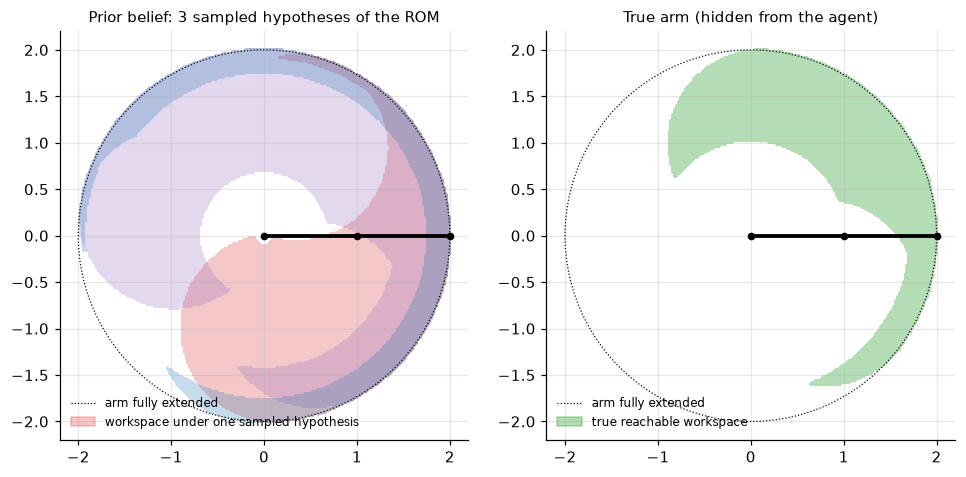

In [3]:
class Belief:
    def __init__(self, n_particles=32, intervals=None):
        self.n = n_particles
        self.intervals = PRIOR.copy() if intervals is None else np.array(intervals, float)
        self.resample()

    def resample(self):
        lo, hi = self.intervals[:, 0], self.intervals[:, 1]
        self.particles = rng.uniform(lo, hi, size=(self.n, 4))

    def update(self, q, a, q_obs):
        # q: state before the step, a: action, q_obs: observed state after the step (all shape (2,))
        for j in range(2):
            cmd = q[j] + a[j]
            lo_idx, hi_idx = 2*j, 2*j+1
            if abs(q_obs[j] - cmd) > TOL:                # clipped -> limit known exactly
                idx = lo_idx if cmd < q_obs[j] else hi_idx
                self.intervals[idx] = [q_obs[j], q_obs[j]]
            else:                                         # not clipped -> limit lies beyond q_obs
                self.intervals[lo_idx, 1] = min(self.intervals[lo_idx, 1], q_obs[j])
                self.intervals[hi_idx, 0] = max(self.intervals[hi_idx, 0], q_obs[j])
        self.resample()

    def width(self):
        return float(np.sum(self.intervals[:, 1] - self.intervals[:, 0]))

    def key(self, res=0.1):
        # Discretized summary used as a cache key: (midpoint, width) of each interval, rounded.
        mid = (self.intervals[:, 0] + self.intervals[:, 1]) / 2
        wid = self.intervals[:, 1] - self.intervals[:, 0]
        return tuple(np.round(np.concatenate([mid, wid]) / res).astype(int))

    def copy(self):
        return Belief(self.n, self.intervals.copy())

# A quick look: what the agent believes at the start vs. what is true.
true_lim_demo = np.array([-0.65, 1.45, -1.07, 2.06])
b = Belief()
fig, ax = plt.subplots(1, 2, figsize=(9, 4.3))
circ = np.linspace(0, 2*np.pi, 200)
for a_ in ax:
    a_.plot((L1+L2)*np.cos(circ), (L1+L2)*np.sin(circ), ls=':', color='k', lw=0.8, label='arm fully extended')
    draw_arm(a_, np.zeros(2)); a_.set_aspect('equal'); a_.set_xlim(-2.2, 2.2); a_.set_ylim(-2.2, 2.2)
for i, p in enumerate(b.particles[:3]):
    draw_workspace(ax[0], p, color=['#d62728', '#9467bd', '#1f77b4'][i], alpha=0.25, label='workspace under one sampled hypothesis' if i == 0 else None)
draw_workspace(ax[1], true_lim_demo, label='true reachable workspace')
ax[0].set_title('Prior belief: 3 sampled hypotheses of the ROM', fontsize=10); ax[1].set_title('True arm (hidden from the agent)', fontsize=10)
for a_ in ax: a_.legend(loc='lower left', fontsize=8)
plt.tight_layout(); plt.show()


## 3. Planner: random shooting with an optional warm-start cache

**Cost** of a candidate action sequence: expected final distance to the goal over belief particles, plus a tiny action penalty. Because the expectation is over hypotheses, a plan that reaches the goal under some limits but gets clipped under others scores badly; the planner naturally prefers plans that are robust to the uncertainty.

**Random shooting** here samples smooth sequences: a random base displacement per sequence plus per-step noise. The planner is **anytime**: it evaluates batches of sequences and stops as soon as the best expected cost is *good enough*, or as a backstop when several consecutive batches fail to improve it, or when the sample budget is exhausted. "Good enough" has to be relative to the belief: under uncertainty a goal at the edge of the range of motion cannot be reached under every hypothesis, so the expected cost has an irreducible floor. We compute that floor (the expected distance from the goal to the nearest reachable point, over particles) and stop once the plan is within a fixed margin of it. The number of samples it needed (and the wall-clock time) is our measure of *planning speed*.

**Cache.** A dictionary from a discretized (goal, belief) key to the best few action sequences found for it. With a cache, the planner's *first* batch is the cached sequences plus small perturbations of them. If those are already good enough, the planner stops after that batch — a lookup with a little refinement — and otherwise it falls back to ordinary shooting. Where cache entries come from is the subject of §5.

In [4]:
def plan_cost(q0, actions, particles, goal):
    qf = rollout(q0, actions, particles)                                   # (K, P, 2)
    dist = np.linalg.norm(fk(qf) - goal, axis=-1).mean(1)                  # expectation over particles
    return dist + 0.001 * np.abs(actions).sum((1, 2))

def cost_floor(particles, goal, n=48):
    # Expected (over particles) distance from the goal to the nearest reachable end-effector position:
    # a lower bound on the achievable plan cost under this belief. If some inverse-kinematics solution
    # lies inside a particle's joint box the distance is 0; otherwise the nearest reachable point lies on
    # the image of the box boundary or of the arm's singular configurations (elbow straight or folded).
    lo1, hi1, lo2, hi2 = particles.T                                             # (P,) each
    r = np.linalg.norm(goal); c2 = np.clip((r**2 - L1**2 - L2**2) / (2*L1*L2), -1, 1)
    inside = np.zeros(len(particles), bool)
    if abs((r**2 - L1**2 - L2**2) / (2*L1*L2)) <= 1:
        for t2 in [np.arccos(c2), -np.arccos(c2)]:
            t1 = np.arctan2(goal[1], goal[0]) - np.arctan2(L2*np.sin(t2), L1 + L2*np.cos(t2))
            t1 = (t1 + np.pi) % (2*np.pi) - np.pi
            inside |= (lo1 <= t1) & (t1 <= hi1) & (lo2 <= t2) & (t2 <= hi2)
    u = np.linspace(0, 1, n)[None]                                                # (1, n)
    e1 = lo1[:, None] + (hi1 - lo1)[:, None] * u; e2 = lo2[:, None] + (hi2 - lo2)[:, None] * u
    curves = [np.stack([e1, np.broadcast_to(lo2[:, None], e1.shape)], -1), np.stack([e1, np.broadcast_to(hi2[:, None], e1.shape)], -1),
              np.stack([np.broadcast_to(lo1[:, None], e2.shape), e2], -1), np.stack([np.broadcast_to(hi1[:, None], e2.shape), e2], -1)]
    for s_ in [0.0, np.pi, -np.pi]:                                               # singular elbow angles, if within limits
        t2 = np.clip(np.full_like(lo2, s_), lo2, hi2)
        curves.append(np.stack([e1, np.broadcast_to(t2[:, None], e1.shape)], -1))
    Q = np.concatenate(curves, 1)                                                 # (P, 7n, 2)
    d = np.linalg.norm(fk(Q) - goal, axis=-1).min(1)
    return np.where(inside, 0.0, d).mean()

def sample_actions(k):
    base = rng.uniform(-DQ_MAX, DQ_MAX, size=(k, 1, 2))
    return np.clip(base + rng.normal(0, 0.15*DQ_MAX, size=(k, H, 2)), -DQ_MAX, DQ_MAX)

class Planner:
    def __init__(self, batch=64, max_batches=25, threshold=0.08, patience=8, cache=None, noise=0.05):
        self.batch, self.max_batches, self.threshold, self.patience = batch, max_batches, threshold, patience
        self.cache = cache            # None, or dict: key -> list of (cost, actions)
        self.noise = noise
        self.stats = []               # one record per call to plan()

    def _warm_start(self, key):
        if self.cache is None or key not in self.cache:
            return None
        seeds = np.stack([a for _, a in self.cache[key]])
        reps = max(1, self.batch // len(seeds))
        pert = np.repeat(seeds, reps, 0) + rng.normal(0, self.noise, size=(len(seeds)*reps, H, 2))
        return np.clip(np.concatenate([seeds, pert]), -DQ_MAX, DQ_MAX)

    def plan(self, q0, belief, goal, key=None):
        t0 = time.perf_counter()
        best_c, best_a, n, stale = np.inf, None, 0, 0
        target = cost_floor(belief.particles, goal) + self.threshold    # "good enough" is relative to what is achievable
        ws = self._warm_start(key)
        for b in range(self.max_batches):
            A = ws if (b == 0 and ws is not None) else sample_actions(self.batch)
            c = plan_cost(q0, A, belief.particles, goal)
            i = int(np.argmin(c)); n += len(A)
            if c[i] < 0.99 * best_c: best_c, best_a, stale = c[i], A[i], 0    # meaningful improvement
            else: stale += 1
            if best_c < target or stale >= self.patience: break        # good enough, or converged
        self.stats.append(dict(samples=n, time=time.perf_counter() - t0, cost=best_c, hit=ws is not None))
        return best_a, best_c

def store(cache, key, cost, actions, keep=4):
    lst = cache.setdefault(key, [])
    lst.append((cost, actions.copy()))
    lst.sort(key=lambda x: x[0]); del lst[keep:]

def task_key(goal, belief, res=0.1):
    return (tuple(np.round(goal / res).astype(int)), belief.key(res))


## 4. Warm-up: one goal, no uncertainty

The most trivial version of "learning to plan": the belief is a point mass at the true limits and there is a single goal. Plan once, memorize the answer, and every later call is a lookup. This is only a sanity check that the machinery works; it says nothing about generalization across tasks or beliefs.

plan from scratch :    653 samples    1.49 ms  cost 0.117
cache lookup      :     65 samples    0.24 ms  cost 0.046


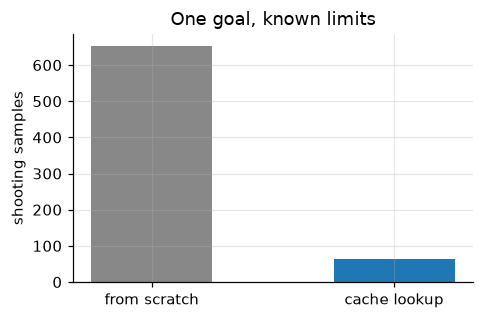

In [5]:
true_lim = np.array([-2.0, 2.5, -2.2, 2.4])
known = Belief(n_particles=1, intervals=np.stack([true_lim, true_lim], 1))
goal0 = np.array([0.8, 1.2]); q0 = np.zeros(2)

cache = {}
scratch, cached = Planner(cache=None), Planner(cache=cache)
k = task_key(goal0, known)
a, c = scratch.plan(q0, known, goal0)          # solve once ...
store(cache, k, c, a)                           # ... and memorize
for _ in range(10):
    scratch.plan(q0, known, goal0)
    cached.plan(q0, known, goal0, key=k)

def summarize(stats):
    return dict(samples=np.mean([s['samples'] for s in stats]), time=np.mean([s['time'] for s in stats]),
                cost=np.mean([s['cost'] for s in stats]))
s1, s2 = summarize(scratch.stats[1:]), summarize(cached.stats)
print(f"plan from scratch : {s1['samples']:6.0f} samples  {1e3*s1['time']:6.2f} ms  cost {s1['cost']:.3f}")
print(f"cache lookup      : {s2['samples']:6.0f} samples  {1e3*s2['time']:6.2f} ms  cost {s2['cost']:.3f}")

fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(['from scratch', 'cache lookup'], [s1['samples'], s2['samples']], color=[C['scratch'], C['memo']], width=0.5)
ax.set_ylabel('shooting samples'); ax.set_title('One goal, known limits'); plt.tight_layout(); plt.show()


## 5. Full loop: dream, plan, execute, update

Now the interesting version. Each run has:

- a **true arm** with limits drawn from the prior (hidden from the agent);
- a **task distribution**: six goals, sampled from the true arm's reachable workspace so that every task is solvable. Half of the goal configurations sit exactly at a joint limit — tasks at the edge of the range of motion. These are the tasks that incidentally reveal the limits;
- a sequence of episodes. Each episode: sample a goal, plan from $q = 0$ under the current belief, execute open-loop on the true arm, update the belief from what was observed.

### Dreaming

Before each episode, the agent dreams `n_dreams` times. One dream:

1. Draw a particle from the current belief and treat it as the true ROM.
2. Draw a goal from the task distribution, plan for it under the *current* belief (exactly as the agent would in reality), and imagine executing that plan on the hypothetical arm. Update a copy of the belief with the imagined observations. This is a sample of the agent's **next belief**.
3. Solve every goal in the task distribution under the imagined next belief, and store the solutions in the cache.

Step 2 matters: the imagined execution uses the plan the agent would actually execute, so imagined next beliefs are distributed like real next beliefs. If dreams imagined arbitrary motions instead, they would predict belief revisions that never happen.

Whenever the agent plans for real, it stores that plan in the cache as well (memorization from experience). This happens in every condition, so the comparison in §6 isolates the effect of dreaming.

### Three agents

- **scratch**: no cache at all;
- **memo**: cache from experience only (`n_dreams = 0`);
- **dream**: cache from experience plus dreams.

All three see the same true arm and the same goal sequence for a given seed.

In [6]:
def sample_goals(true_lim, n, arm_rng, p_edge=0.5):
    # Goal configurations reachable under the true limits and within the plan's reach from q=0.
    # With probability p_edge per joint, the configuration sits exactly at a joint limit.
    lo = np.maximum(true_lim[[0, 2]], -DQ_MAX*H*0.8); hi = np.minimum(true_lim[[1, 3]], DQ_MAX*H*0.8)
    q = arm_rng.uniform(lo, hi, size=(n, 2))
    snap = arm_rng.random((n, 2)) < p_edge
    side = arm_rng.random((n, 2)) < 0.5
    return fk(np.where(snap, np.where(side, lo, hi), q))

def execute_and_update(arm, belief, actions):
    for t in range(H):
        q = arm.q.copy(); q_obs = arm.execute(actions[t]); belief.update(q, actions[t], q_obs)

def dream_once(belief, goals, cache, planner):
    hypothesis = belief.particles[rng.integers(belief.n)]         # 1. pretend this is the true ROM
    goal = goals[rng.integers(len(goals))]
    a, _ = planner.plan(np.zeros(2), belief, goal, key=task_key(goal, belief))
    imagined = belief.copy()
    execute_and_update(TrueArm(hypothesis), imagined, a)           # 2. imagined next belief
    for g in goals:                                                # 3. memorize plans for it
        key = task_key(g, imagined)
        a, c = planner.plan(np.zeros(2), imagined, g, key=key)
        store(cache, key, c, a)

def run(n_episodes=20, n_dreams=0, use_cache=True, seed=1):
    global rng
    rng = np.random.default_rng(seed)
    arm_rng = np.random.default_rng(seed + 100)
    true_lim = arm_rng.uniform(PRIOR[:, 0], PRIOR[:, 1])
    goals = sample_goals(true_lim, 6, arm_rng)
    goal_seq = arm_rng.integers(len(goals), size=n_episodes)
    cache = {} if use_cache else None
    planner, dream_planner = Planner(cache=cache), Planner(cache=cache)
    belief = Belief()
    log, trajs = [], []
    for ep in range(n_episodes):
        if use_cache:
            for _ in range(n_dreams):
                dream_once(belief, goals, cache, dream_planner)
        goal = goals[goal_seq[ep]]
        key = task_key(goal, belief)
        a, c = planner.plan(np.zeros(2), belief, goal, key=key)
        arm = TrueArm(true_lim)
        execute_and_update(arm, belief, a)
        if use_cache:
            store(cache, key, c, a)
        s = planner.stats[-1]
        log.append(dict(ep=ep, width=belief.width(), err=float(np.linalg.norm(fk(arm.q) - goal)),
                        samples=s['samples'], time=s['time'], hit=s['hit'], goal=goal, q_final=arm.q.copy()))
    return log, belief, true_lim, goals

SEED = 4
log_scratch, _, true_lim, goals = run(use_cache=False, seed=SEED)
log_memo, _, _, _ = run(n_dreams=0, seed=SEED)
log_dream, belief, _, _ = run(n_dreams=8, seed=SEED)

print("true limits         :", np.round(true_lim, 3))
print("final belief (dream):"); print(np.round(belief.intervals, 3))


true limits         : [-0.926  2.328 -2.571  0.831]
final belief (dream):
[[-0.926 -0.926]
 [ 2.328  3.142]
 [-2.571 -2.571]
 [ 0.831  0.831]]


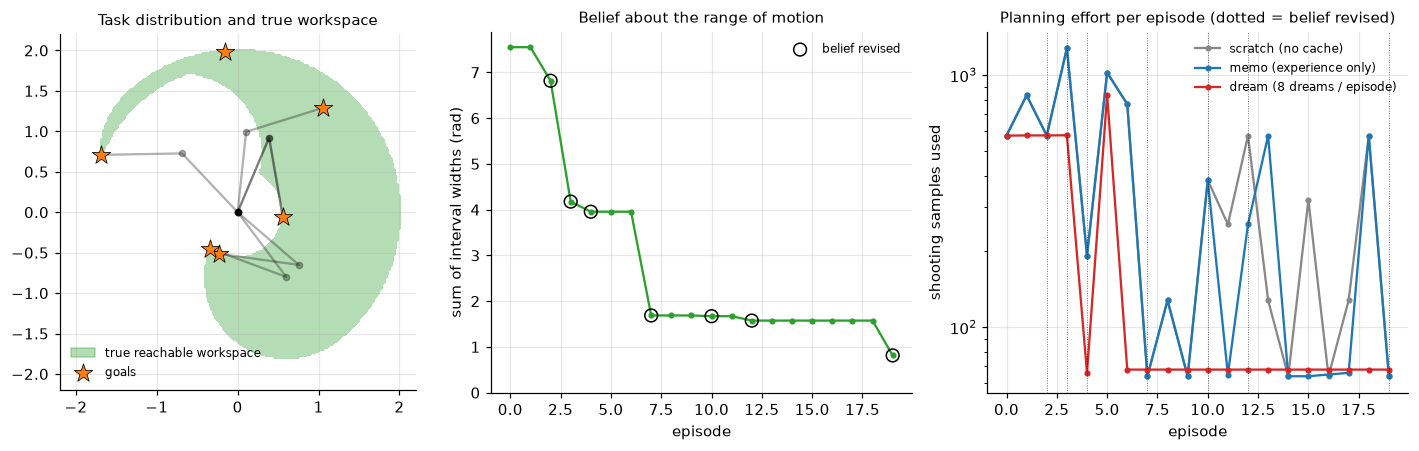

In [7]:
fig = plt.figure(figsize=(13, 4.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1.1, 1.3, 1.3])

# (a) the task: true workspace, goals, and the final arm configurations reached by the dreaming agent
ax = fig.add_subplot(gs[0])
draw_workspace(ax, true_lim, label='true reachable workspace')
for l in log_dream[-6:]:
    draw_arm(ax, l['q_final'], color='k', alpha=0.3, lw=1.5)
ax.scatter(goals[:, 0], goals[:, 1], marker='*', s=160, color=C['goal'], edgecolor='k', lw=0.5, zorder=5, label='goals')
ax.set_aspect('equal'); ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2)
ax.set_title('Task distribution and true workspace', fontsize=10); ax.legend(loc='lower left', fontsize=8)

# (b) belief width per episode, with the episodes where it changed marked
ax = fig.add_subplot(gs[1])
w = [l['width'] for l in log_dream]
ax.plot(range(len(w)), w, '-o', ms=3, color=C['belief'])
changed = [i for i in range(1, len(w)) if w[i] < w[i-1] - 1e-9]
ax.scatter(changed, [w[i] for i in changed], s=70, facecolor='none', edgecolor='k', zorder=5, label='belief revised')
ax.set_xlabel('episode'); ax.set_ylabel('sum of interval widths (rad)'); ax.set_ylim(bottom=0)
ax.set_title('Belief about the range of motion', fontsize=10); ax.legend(fontsize=8)

# (c) planning effort per episode
ax = fig.add_subplot(gs[2])
for lg, name, lab in [(log_scratch, 'scratch', 'scratch (no cache)'), (log_memo, 'memo', 'memo (experience only)'), (log_dream, 'dream', 'dream (8 dreams / episode)')]:
    ax.plot([l['ep'] for l in lg], [l['samples'] for l in lg], '-o', ms=3, color=C[name], label=lab)
for i in changed: ax.axvline(i, color='k', lw=0.6, ls=':', alpha=0.6)
ax.set_yscale('log'); ax.set_xlabel('episode'); ax.set_ylabel('shooting samples used')
ax.set_title('Planning effort per episode (dotted = belief revised)', fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


**How to read this.** The memo agent is fast whenever the goal *and* the belief have both been seen before; every time the belief is revised (circled in the right panel), its cache is stale and it pays the full planning cost again. The dreaming agent has usually already solved the goals under the revised belief, because that revision was one of the futures it imagined. Its remaining expensive episodes are the ones where the realized belief fell outside what it dreamed — with more dreams, those become rarer. That is the sweep in the next section.

One caveat to keep in mind: this is a single seed, and which episodes are expensive depends on the goal sequence. The next section averages over seeds.

## 6. Sweep: how many dreams do we need? (P1)

We vary `n_dreams` and average over several seeds (each seed = a different true arm and goal sequence). To keep the comparison fair, all conditions plan for real with the same planner settings; only the contents of the cache differ. We report:

- mean shooting samples per real planning call (planning speed);
- the **cache hit rate on episodes where the belief was just revised** — the episodes where memorization from experience cannot help, and where dreaming is supposed to;
- final-step error, to check that faster planning is not buying speed with worse plans.

In [ ]:
SEEDS = list(range(1, 13))
N_DREAMS = [0, 1, 2, 4, 8, 16]

def is_revision(lg):
    return np.array([False] + [lg[i]['width'] < lg[i-1]['width'] - 1e-9 for i in range(1, len(lg))])

LOGS = {}                                         # (condition, seed) -> per-episode log
for seed in SEEDS:
    LOGS[('scratch', seed)] = run(use_cache=False, seed=seed)[0]
    for nd in N_DREAMS:
        LOGS[(nd, seed)] = run(n_dreams=nd, seed=seed)[0]

def per_seed(cond, field, mask=None):
    out = []
    for seed in SEEDS:
        lg = LOGS[(cond, seed)]; v = np.array([l[field] for l in lg], float)
        m = np.ones(len(lg), bool) if mask is None else mask(lg)
        out.append(v[m].mean() if m.any() else np.nan)
    return np.array(out)

def mean_se(x):
    x = x[~np.isnan(x)]; return x.mean(), x.std(ddof=1) / np.sqrt(len(x))

print(f"{'condition':>12} {'samples/plan':>13} {'ms/plan':>9} {'hit@revised':>12} {'final err':>10}")
for cond in ['scratch'] + N_DREAMS:
    name = 'scratch' if cond == 'scratch' else f'{cond} dreams'
    hit = '-' if cond == 'scratch' else f"{mean_se(per_seed(cond, 'hit', is_revision))[0]:12.2f}"
    print(f"{name:>12} {mean_se(per_seed(cond, 'samples'))[0]:13.0f} {1e3*mean_se(per_seed(cond, 'time'))[0]:9.2f} {hit:>12} {mean_se(per_seed(cond, 'err'))[0]:10.3f}")


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
x = np.arange(len(N_DREAMS)); xt = [str(n) for n in N_DREAMS]

def errbar(a, field, color, mask=None, label=None):
    ms_ = [mean_se(per_seed(nd, field, mask)) for nd in N_DREAMS]
    a.errorbar(x, [m for m, _ in ms_], yerr=[e for _, e in ms_], fmt='-o', color=color, capsize=3, label=label)

def baseline(a, field, label):
    m, e = mean_se(per_seed('scratch', field))
    a.axhline(m, color=C['scratch'], ls='--', label=label); a.axhspan(m - e, m + e, color=C['scratch'], alpha=0.15, lw=0)

errbar(ax[0], 'samples', C['dream'], label='with cache'); baseline(ax[0], 'samples', 'scratch (no cache)')
ax[0].set_ylabel('shooting samples per plan'); ax[0].set_title('Planning effort vs. dreams', fontsize=10); ax[0].legend(fontsize=8); ax[0].set_ylim(bottom=0)
errbar(ax[1], 'hit', C['dream'], mask=is_revision)
ax[1].set_ylim(0, 1.05); ax[1].set_ylabel('cache hit rate'); ax[1].set_title('Hit rate on belief-revision episodes', fontsize=10)
errbar(ax[2], 'err', C['dream'], label='with cache'); baseline(ax[2], 'err', 'scratch (no cache)')
ax[2].set_ylim(bottom=0); ax[2].set_ylabel('final end-effector error'); ax[2].set_title('Plan quality', fontsize=10); ax[2].legend(fontsize=8)
for a in ax:
    a.set_xticks(x); a.set_xticklabels(xt); a.set_xlabel('dreams per episode')
fig.suptitle(f'Averages over {len(SEEDS)} seeds (error bars: standard error)', fontsize=10, y=1.02)
plt.tight_layout(); plt.show()

# Where does the saving come from? Split episodes into those right after a belief revision and the rest.
fig, ax = plt.subplots(figsize=(6.5, 3.6))
conds = [('scratch', 'scratch'), (0, 'memo (0 dreams)'), (2, '2 dreams'), (8, '8 dreams')]
masks = [('belief just revised', is_revision), ('belief unchanged', lambda lg: ~is_revision(lg))]
wdt = 0.8 / len(conds)
for j, (cond, lab) in enumerate(conds):
    ms_ = [mean_se(per_seed(cond, 'samples', mk)) for _, mk in masks]
    color = C['scratch'] if cond == 'scratch' else (C['memo'] if cond == 0 else C['dream'])
    ax.bar(np.arange(2) + (j - 1.5)*wdt, [m for m, _ in ms_], wdt, yerr=[e for _, e in ms_], capsize=3, color=color,
           alpha=1.0 if cond in ('scratch', 0) else (0.55 if cond == 2 else 0.9), label=lab)
ax.set_xticks(range(2)); ax.set_xticklabels([n for n, _ in masks]); ax.set_ylabel('shooting samples per plan')
ax.set_title('Planning effort by episode type', fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


**Reading the sweep.** Memorization from experience alone (0 dreams) already removes the cost of repeated (goal, belief) pairs. What it cannot do is prepare for a belief the agent has not held yet; on the episodes right after a belief revision it plans from scratch, and its hit rate on those episodes is low. Dreaming fills exactly that gap: as the number of dreams grows, the realized next belief is more likely to be one the agent has already solved for, the hit rate on revision episodes rises, and the average planning effort falls — without hurting plan quality. Error bars are standard errors over seeds. The bar chart splits episodes by whether the belief was just revised. Right after a revision, memo is no better than scratch — its cache holds nothing for the new belief — while the dreaming agent is two to three times cheaper. Dreaming also helps on unchanged-belief episodes, for a subtler reason: memo only knows the (goal, belief) pairs it has actually executed, whereas each dream solves *every* goal under the imagined belief, including the current one when the imagined execution reveals nothing new.

Why does the hit rate not reach 1? Two reasons worth thinking about. (i) The cache key discretizes the belief; a dreamed limit value and the real one can round to different keys. (ii) Dreams sample *one* particle as the hypothetical truth; with few dreams, the sampled hypotheses may all miss the region where the true limit lies. Both point to the same fix: replace the exact-match cache with something that generalizes across nearby beliefs (nearest-neighbor lookup, or a learned model from (goal, belief) to a plan).

## 7. Belief collapse over executions (P2)

The other half of the loop: does the belief actually converge to the true range of motion as the agent accumulates real executions? Since information gathering is incidental, this depends on the task distribution steering the arm into its limits. Below, belief width over episodes averaged over seeds, for three task distributions: every goal at the edge of the range of motion (`p_edge = 1`), the default where half of the goal configurations sit at a limit (`p_edge = 0.5`), and strictly interior goals (`p_edge = 0`).

In [ ]:
def width_curve(p_edge, seeds, n_episodes=40):
    curves = []
    for seed in seeds:
        global rng
        rng = np.random.default_rng(seed)
        arm_rng = np.random.default_rng(seed + 100)
        true_lim = arm_rng.uniform(PRIOR[:, 0], PRIOR[:, 1])
        goals = sample_goals(true_lim, 6, arm_rng, p_edge=p_edge)
        belief, planner = Belief(), Planner()
        ws = []
        for ep in range(n_episodes):
            goal = goals[arm_rng.integers(len(goals))]
            a, _ = planner.plan(np.zeros(2), belief, goal)
            execute_and_update(TrueArm(true_lim), belief, a)
            ws.append(belief.width())
        curves.append(ws)
    return np.array(curves)

w_all = width_curve(1.0, SEEDS); w_edge = width_curve(0.5, SEEDS); w_int = width_curve(0.0, SEEDS)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for W, name, color in [(w_all, 'all goals at edge of ROM (p_edge = 1)', C['memo']), (w_edge, 'half of goals at edge (p_edge = 0.5)', C['belief']), (w_int, 'interior goals only (p_edge = 0)', C['goal'])]:
    m, se = W.mean(0), W.std(0, ddof=1) / np.sqrt(len(W))
    ax.plot(m, color=color, lw=2, label=name); ax.fill_between(range(len(m)), m - se, m + se, color=color, alpha=0.25, lw=0)
ax.text(0.99, 0.62, f'mean over {len(SEEDS)} seeds, band = standard error', transform=ax.transAxes, ha='right', fontsize=8, color='0.4')
ax.axhline(0, color='k', lw=0.8); ax.set_ylim(bottom=-0.2)
ax.set_xlabel('episode'); ax.set_ylabel('sum of interval widths (rad)')
ax.set_title('Belief collapse under incidental information gathering', fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("mean final width: p_edge=1: %.2f, p_edge=0.5: %.2f, p_edge=0: %.2f (prior: %.2f)" % (w_all[:, -1].mean(), w_edge[:, -1].mean(), w_int[:, -1].mean(), Belief().width()))


**Reading this.** The more the task distribution pushes the arm toward its limits, the faster the belief collapses: every reach toward the edge that overshoots under some hypotheses gets clipped, and one clip pins a limit exactly. The residual width has two sources: limits that no goal happens to touch, and plans that approach a limit without crossing it — the planner minimizes *expected* cost, so it tends to stop just short of where the hypotheses disagree, and the "not clipped" update then narrows the interval without pinning it. Even with every goal at the edge (`p_edge = 1`) about a radian of total width survives for this reason. With interior goals the belief shrinks only through the "not clipped" updates (which rule out limits the arm has already moved past) and then plateaus: the agent never learns where the limits are because nothing it does depends on them. This is the sense in which incidental information gathering is task-dependent — and the motivation for a *deliberate* version in which the planner is rewarded for reducing uncertainty.

## 8. Suggestions for extensions

Roughly in order of how much they change the story:

1. **Generalizing cache.** Replace the exact-match dictionary with nearest-neighbor lookup over (goal, belief summary), or train a small regressor from (goal, belief) to an action sequence on the dreamed data and use its output as the warm start. Then the hit rate is no longer limited by discretization, and dream data from *nearby* beliefs helps.
2. **Deliberate information gathering.** Add an expected-information-gain term to the plan cost, or plan in the belief space by simulating the belief update inside the rollout (a proper POMDP treatment). Compare how quickly the belief collapses against the incidental version in §7.
3. **Multi-step dreams.** Dreams currently look one episode ahead. Chain them: imagine two or three episodes and memorize under each intermediate belief. Where does the extra dreaming budget pay off most?
4. **Richer unknowns.** Move from independent joint limits to a coupled range of motion (e.g. a reachable region in joint space) so the belief no longer factorizes and the exact interval update must be replaced by weighting and resampling particles.
5. **Non-stationary ROM.** Let the true limits drift slowly over time (a person's range of motion changes with fatigue or recovery) and see how the agent has to keep dreaming rather than dream once and stop.
6. **Dynamics.** Switch to torque control with hidden link masses. Note that this requires a dynamic simulator; under kinematic control the masses are unobservable, which is why they were not a good unknown for this notebook.